# Porto — mạng đường và map matching trên mẫu vùng C mở rộng 8×8 km

Theo yêu cầu, mở rộng vùng C từ khoảng 4×4 lên 8×8 km, giữ tâm C. Bbox `[west, south, east, north]`
`[-8.654504338104756, 41.12745663346633, -8.558716252527459, 41.199844416439696]`.
Notebook **mới và tự chứa** này triển khai bước 2–3: mạng đường có hướng, đếm cạnh,
matching toàn bộ 9.501 chuyến vùng C mở rộng trong mẫu EDA, QA, quan sát partial-edge và độ phủ cạnh–khung giờ.
Hai notebook EDA và mô hình cũ được giữ nguyên. Chưa train B0/B1/M1/M2, đánh giá ETA
hoặc xây web/demo. Smoke/pilot không đủ để kết luận tình trạng giao thông.

GPS được lấy từ **đúng cache mẫu EDA**; không đọc lại train.csv, không lấy thêm chuyến
ngoài mẫu đã thống nhất. Mẫu EDA vốn ưu tiên giờ khởi hành cao điểm và không đại diện
tỷ lệ nhu cầu toàn thành phố. Nhóm giờ phân tích dùng giờ từng điểm.

Mạng đường lấy từ OpenStreetMap qua OSMnx. Nếu snapshot đã lưu bao phủ vùng + đệm,
tái sử dụng và ghi nguồn/ngày tải/hash; nếu không có mới tải. OSM hiện tại có thể
khác đường phố khi thu GPS năm 2013. Đồ thị đường **không được suy ra từ GPS**.

> **Bố cục repo:** notebook đã được chuyển vào thư mục theo bước và tự tìm thư mục gốc. Các output đang hiển thị được giữ từ lượt thực thi trước khi sắp xếp đường dẫn; không chạy lại matching/train trong bước sắp xếp này. Run All tiếp theo sẽ dùng đường dẫn mới và cache hợp lệ.

## A. Cấu hình và cài đặt

Mặc định dùng vùng C mở rộng và đủ 9.501 chuyến có GPS trong vùng thuộc mẫu train đã khảo sát.
Để quay lại pilot nhỏ, đặt `max_trips=300`. Khi lấy hết population trong vùng, tỷ lệ
các nhóm giờ là tỷ lệ có sẵn trong mẫu EDA, không ép 70/30 bằng cách bỏ chuyến.
`graph_buffer_m` cung cấp ngữ cảnh matching ngoài vùng; thống kê phân tích cuối chỉ
giữ phần cạnh thực sự bên trong bbox. Không nới vùng chỉ để ép số cạnh đạt 5.000–7.000.

In [1]:
from pathlib import Path
import os
# Locate the repository from either its root or a notebook subfolder.
_current_dir = Path.cwd().resolve()
ROOT = next((candidate for candidate in (_current_dir, *_current_dir.parents)
             if (candidate / "notebooks").is_dir() and (candidate / "requirements").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the cloned repository (notebooks/ and requirements/ must exist).")
CFG = {
    "region_name": "C_8km", "nominal_side_km": 8.0,
    "region_center_source": "Center of C_4km; expanded in EPSG:32629 and enclosed by WGS84 bbox",
    "bbox": [-8.654504338104756, 41.12745663346633, -8.558716252527459, 41.199844416439696],
    "eda_latest": "outputs/region_eda/latest_run.json",
    "cache_dir": "cache/region_pilot", "output_dir": "outputs/region_pilot",
    "csv_dir": "outputs/csv", "metric_crs": "EPSG:32629", "timezone": "Europe/Lisbon",
    "graph_buffer_m": 200, "seed": 313, "max_trips": 9501,
    "reuse_raw_overpass_cache": True, "source_overpass_cache_dir": "cache/osmnx_http",
    "matching_workers": max(1, min(3, (os.cpu_count() or 2)-1)),
    "peak_fraction": .70, "morning_share_of_peak": .50,
    "peak_windows": {"morning_peak": [7,9], "evening_peak": [16,19]},
    "gps_interval_s": 15, "min_points": 4, "max_points_per_subtrajectory": 180,
    "matching_batch_size": 25, "candidate_radius_m": 60, "gps_error_m": 25,
    "hmm_lattice_width": 12, "microedge_max_m": 60,
    "max_match_error_m": 45, "max_mean_match_error_m": 30,
    "min_matched_point_ratio": .70, "min_retained_interval_ratio": .60,
    "max_matched_speed_kmh": 140, "max_detour_ratio": 5., "detour_floor_m": 40,
    "backward_jitter_m": 5, "time_bin_hours": 1,
    "coverage_min_trips": 5, "coverage_min_taxis": 3, "coverage_min_days": 3,
    "reuse_existing_graph": True, "allow_graph_download": True, "graph_timeout_s": 90,
    "force_graph": False, "force_rematch": False,
    "cpu_threads": max(1, min(4, (os.cpu_count() or 2)-1)),
    "qa_plot_subtrajectories": 6,
}
for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[name] = str(CFG["cpu_threads"])

In [2]:
# Nếu thiếu package, bỏ dấu # ở dòng dưới, chạy rồi restart kernel.
# %pip install -r "{ROOT / 'requirements/requirements_region_pilot.txt'}"

In [3]:
import ast, contextlib, hashlib, importlib.util, importlib.metadata, inspect, json, math, time, sys
from datetime import datetime, timezone
import logging
REQUIRED = {"numpy":"numpy", "pandas":"pandas", "pyarrow":"pyarrow", "shapely":"shapely",
            "geopandas":"geopandas", "pyproj":"pyproj", "osmnx":"osmnx", "networkx":"networkx",
            "matplotlib":"matplotlib", "psutil":"psutil", "leuvenmapmatching":"leuvenmapmatching", "rtree":"rtree", "joblib":"joblib"}
missing = [dist for mod, dist in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    raise RuntimeError("Thiếu dependencies: " + ", ".join(missing) + "; cài ở cell hướng dẫn.")
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import psutil
import shapely
from shapely.geometry import Point, LineString, box
from shapely.ops import substring
from pyproj import Transformer
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from IPython.display import display, Markdown
logging.getLogger("be.kuleuven.cs.dtai.mapmatching").setLevel(logging.ERROR)
VERSIONS = {dist:importlib.metadata.version(dist) for dist in REQUIRED.values()}
OPTIONAL = {name:(importlib.metadata.version(name) if importlib.util.find_spec(name) else "not installed") for name in ["fastmm","fmm"]}
display(pd.Series({**VERSIONS, **OPTIONAL}, name="version").to_frame())
print("Matcher: Leuven HMM. Không dùng nearest-edge thay map matching.")
print("FMM/fastmm không bắt buộc; API FMM chưa được xác minh trong môi trường này.")

def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda:handle.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def write_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+".tmp")
    payload=json.dumps(value,ensure_ascii=False,indent=2,default=str)
    # Windows readers or antivirus can briefly deny replacement of an open file.
    for attempt in range(10):
        try:
            temp.write_text(payload,encoding="utf-8")
            temp.replace(path)
            return
        except PermissionError:
            if attempt==9:
                raise
            time.sleep(min(.4,.025*(2**attempt)))

def csv_path(path):
    return ROOT/CFG["csv_dir"]/Path(path).resolve().relative_to((ROOT/"outputs").resolve()).with_suffix(".csv")

def write_table(frame,path,csv=False):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(".tmp.parquet")
    frame.to_parquet(temp,index=False); temp.replace(path)
    if csv:
        target=csv_path(path); target.parent.mkdir(parents=True,exist_ok=True)
        frame.to_csv(target,index=False,encoding="utf-8-sig")

def record_stage(name,status,detail):
    STAGES[name]={"status":status,"detail":str(detail)}
    write_json(RUN/"stage_status.json", STAGES)
    print(f"[{name}] {status}: {detail}")

@contextlib.contextmanager
def timed(name):
    before=time.perf_counter(); rss=psutil.Process().memory_info().rss/2**20
    try:
        yield
    finally:
        row={"stage":name,"seconds":time.perf_counter()-before,"rss_before_mb":rss,
             "rss_after_mb":psutil.Process().memory_info().rss/2**20}
        RUNTIME.append(row); write_json(RUN/"runtime.json",RUNTIME)
        print(f"{name}: {row['seconds']:.1f}s; RSS cuối bước={row['rss_after_mb']:.0f} MiB")

def save_figure(name):
    plt.tight_layout(); plt.savefig(FIGURES/(name+".png"),dpi=150,bbox_inches="tight")
    plt.show(); plt.close()

assert CFG["max_trips"]>0 and CFG["min_points"]>=2 and CFG["max_points_per_subtrajectory"]>=CFG["min_points"]
assert 24 % CFG["time_bin_hours"] == 0
west,south,east,north=CFG["bbox"]
assert -180<west<east<180 and -90<south<north<90
PROJECT=Transformer.from_crs(4326,CFG["metric_crs"],always_xy=True)
UNPROJECT=Transformer.from_crs(CFG["metric_crs"],4326,always_xy=True)
STUDY_POLYGON=shapely.transform(box(*CFG["bbox"]),PROJECT.transform,interleaved=False)
BUFFER_POLYGON=STUDY_POLYGON.buffer(CFG["graph_buffer_m"])
CACHE=ROOT/CFG["cache_dir"]; OUTPUT=ROOT/CFG["output_dir"]
CACHE.mkdir(parents=True,exist_ok=True)
eda_pointer=ROOT/CFG["eda_latest"]
if not eda_pointer.exists():
    raise FileNotFoundError("Chưa có latest_run.json của EDA; chạy porto_region_eda.ipynb trước.")
EDA_RUN=Path(json.loads(eda_pointer.read_text(encoding="utf-8"))["folder"])
EDA_CONFIG=json.loads((EDA_RUN/"config.json").read_text(encoding="utf-8"))
EDA_KEYS=json.loads((EDA_RUN/"cache_keys.json").read_text(encoding="utf-8"))
POINTS_PATH=ROOT/EDA_CONFIG["cache_dir"]/"grid"/EDA_KEYS["grid"]/"point_cells.parquet"
if not POINTS_PATH.exists():
    raise FileNotFoundError(f"Thiếu GPS cache {POINTS_PATH}; chạy lại EDA để tạo cache thật.")
CODE_HASH=stable_hash([c["source"] for c in json.loads((ROOT/"notebooks/02_region_matching/porto_region_pilot.ipynb").read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"])
SOURCE_HASH=file_hash(POINTS_PATH)
RUN_KEY=stable_hash([CFG,VERSIONS,CODE_HASH,SOURCE_HASH])[:20]
RUN=OUTPUT/RUN_KEY; FIGURES=RUN/"figures"
FIGURES.mkdir(parents=True,exist_ok=True)
STAGES={}; RUNTIME=[]
write_json(RUN/"config.json",CFG)
write_json(RUN/"environment.json",{"python":sys.version,"packages":VERSIONS,"optional_matchers":OPTIONAL})
write_json(RUN/"data_source.json",{"eda_run":str(EDA_RUN),"eda_cache_keys":EDA_KEYS,"point_cache":str(POINTS_PATH),
    "point_sha256":SOURCE_HASH,"study_start":EDA_CONFIG["study_start"],"study_end":EDA_CONFIG["study_end"],
    "scope":"Only existing EDA sample trips crossing the configured region; no raw train.csv reading or extra trips"})
print("Output:",RUN)
print("CSV:",ROOT/CFG["csv_dir"]/"region_pilot"/RUN_KEY)

,version
numpy,2.1.3
pandas,2.3.2
pyarrow,23.0.1
shapely,2.2.0
geopandas,1.2.0
pyproj,3.8.0
osmnx,2.1.1
networkx,3.5
matplotlib,3.10.0
psutil,7.1.0


Matcher: Leuven HMM. Không dùng nearest-edge thay map matching.
FMM/fastmm không bắt buộc; API FMM chưa được xác minh trong môi trường này.
Output: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_pilot\8946a3b89ff42fa9ba5c
CSV: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\csv\region_pilot\8946a3b89ff42fa9ba5c


## B. Lấy toàn bộ mẫu trong vùng đã chọn và giữ thời gian gốc

Xét chuyến có ít nhất một GPS thực nằm trong vùng, kể cả chuyến bắt đầu bên ngoài.
Không lấy head(N). Chọn có seed, phân bổ ngày trong từng nhóm giờ khởi hành;
70% ngân sách sáng/chiều, 30% ngoài cao điểm nếu đủ tầng. Số ngày/giờ không bị
coi là phân bố nhu cầu. Chuyến chỉ có dây cung cắt vùng nhưng không có GPS trong vùng
không thuộc population này; EDA báo loại bằng chứng đó riêng.

Giữ `original_index`, timestamp UTC và `segment_id` từ EDA. Matching dùng phần GPS
trong vùng đệm, tách khi ra/vào đệm hoặc mất liên tục. Đoạn dài chia thành các batch
có chung đúng một điểm biên để không mất khoảng GPS; context giới hạn có thể làm
giảm chất lượng HMM ở biên batch, được ghi trong QA. Không xóa điểm đứng yên.

In [4]:
def inside_bbox(points,bbox):
    w,s,e,n=bbox
    return points.lon.between(w,e)&points.lat.between(s,n)

def period_at(timestamp):
    local=pd.Timestamp(timestamp,unit="s",tz="UTC").tz_convert(CFG["timezone"])
    minutes=local.hour*60+local.minute
    for name,(a,b) in CFG["peak_windows"].items():
        if a*60<=minutes<b*60:
            return name
    return "off_peak"

def fair_quotas(capacities,budget,seed):
    capacities=pd.Series(capacities,dtype=int)
    quotas=pd.Series(0,index=capacities.index,dtype=int)
    order=np.random.default_rng(seed).permutation(len(capacities))
    remaining=min(int(budget),int(capacities.sum()))
    while remaining:
        eligible=[i for i in order if quotas.iloc[i]<capacities.iloc[i]]
        if not eligible:
            break
        for i in eligible[:remaining]:
            quotas.iloc[i]+=1
        remaining-=min(remaining,len(eligible))
    return quotas

def choose_pilot(points,metadata):
    eligible_ids=set(points.loc[inside_bbox(points,CFG["bbox"]),"trip_id"])
    pool=metadata[metadata.trip_id.isin(eligible_ids)].copy()
    pool["period"]=[period_at(int(t)) for t in pool.timestamp]
    local=pd.to_datetime(pool.timestamp,unit="s",utc=True).dt.tz_convert(CFG["timezone"])
    pool["day"]=local.dt.strftime("%Y-%m-%d")
    groups=["morning_peak","evening_peak","off_peak"]
    weights=np.array([CFG["peak_fraction"]*CFG["morning_share_of_peak"],CFG["peak_fraction"]*(1-CFG["morning_share_of_peak"]),1-CFG["peak_fraction"]])
    budget=min(CFG["max_trips"],len(pool)); capacities=pool.period.value_counts().reindex(groups,fill_value=0).to_numpy()
    wanted=weights*budget; quotas=np.minimum(np.floor(wanted).astype(int),capacities)
    while quotas.sum()<budget:
        eligible=np.flatnonzero(quotas<capacities)
        idx=max(eligible,key=lambda i:(wanted[i]-quotas[i],-i))
        quotas[idx]+=1
    selected=[]; strata=[]
    for gi,name in enumerate(groups):
        frame=pool[pool.period==name].copy()
        counts=frame.groupby("day").size().sort_index()
        daily=fair_quotas(counts,int(quotas[gi]),CFG["seed"]+gi)
        frame["priority"]=[stable_hash([CFG["seed"],str(trip)]) for trip in frame.trip_id]
        for day,quota in daily.items():
            population=frame[frame.day==day].sort_values(["priority","trip_id"])
            selected.append(population.iloc[:int(quota)])
            strata.append({"day":day,"departure_period":name,"pool_trips":len(population),"selected_trips":int(quota),
                           "sampling_fraction_within_eda_pool":quota/len(population)})
    chosen=pd.concat(selected,ignore_index=True).drop(columns="priority")
    assert chosen.trip_id.is_unique and len(chosen)==budget
    return chosen,pd.DataFrame(strata),len(pool),pd.DataFrame({"departure_period":groups,"wanted":wanted,"selected":quotas,"available":capacities})

def split_context_points(points):
    points=points.sort_values(["trip_id","segment_id","original_index"]).copy()
    keep=shapely.covers(BUFFER_POLYGON,shapely.points(points.x.to_numpy(),points.y.to_numpy()))
    points=points.loc[keep].copy()
    previous=points.shift()
    new=points.trip_id.ne(previous.trip_id)|points.segment_id.ne(previous.segment_id)|points.original_index.ne(previous.original_index+1)
    points["context_run"]=new.cumsum()
    subs=[]; skipped=0
    for _,frame in points.groupby("context_run",sort=False):
        if len(frame)<CFG["min_points"]:
            skipped+=1
            continue
        records=frame[["original_index","timestamp","x","y"]].to_dict("records")
        width=CFG["max_points_per_subtrajectory"]
        for start in range(0,len(records)-1,width-1):
            block=records[start:start+width]
            if len(block)<CFG["min_points"]:
                skipped+=1
                continue
            first=frame.iloc[0]
            sid=f"{first.trip_id}:{first.segment_id}:context{int(first.context_run)}:p{block[0]['original_index']}"
            subs.append({"trip_id":str(first.trip_id),"taxi_id":str(first.taxi_id),"subtrajectory_id":sid,
                         "split":"train_pilot","points":block})
    return subs,skipped

with timed("load_eda_and_select_pilot"):
    all_points=pd.read_parquet(POINTS_PATH)
    metadata=pd.read_parquet(EDA_RUN/"selected_trips.parquet")
    for frame in [all_points,metadata]:
        frame["trip_id"]=frame.trip_id.astype(str); frame["taxi_id"]=frame.taxi_id.astype(str)
    starts=all_points.timestamp-CFG["gps_interval_s"]*all_points.original_index
    assert starts.groupby(all_points.trip_id).nunique().max()==1,"Timestamp gốc không nhất quán"
    SELECTED,STRATA,POOL_SIZE,GROUP_QUOTAS=choose_pilot(all_points,metadata)
    PILOT_POINTS=all_points[all_points.trip_id.isin(SELECTED.trip_id)].copy()
    del all_points
    SUBS,SKIPPED_SHORT=split_context_points(PILOT_POINTS)
    PARTS_PATH=CACHE/"samples"/(stable_hash([SOURCE_HASH,CFG["bbox"],CFG["graph_buffer_m"],SELECTED.trip_id.tolist(),CFG["max_points_per_subtrajectory"]])+".jsonl")
    PARTS_PATH.parent.mkdir(parents=True,exist_ok=True)
    PARTS_PATH.write_text("".join(json.dumps(s,ensure_ascii=False)+"\n" for s in SUBS),encoding="utf-8")
    write_table(SELECTED,RUN/"selected_trips.parquet")
    write_table(STRATA,RUN/"sampling_strata.parquet",csv=True)
    write_table(GROUP_QUOTAS,RUN/"sampling_groups.parquet",csv=True)
    write_table(PILOT_POINTS,RUN/"pilot_points.parquet")
    write_json(RUN/"selection_summary.json",{"eligible_eda_trips_with_gps_in_region":POOL_SIZE,
        "selected_trips":len(SELECTED),"selected_taxis":SELECTED.taxi_id.nunique(),"selected_departure_days":SELECTED.day.nunique(),
        "subtrajectories":len(SUBS),"trips_with_context":len({s['trip_id'] for s in SUBS}),"short_context_segments_excluded":SKIPPED_SHORT})
    display(GROUP_QUOTAS)
    record_stage("sample","complete",f"{len(SELECTED)}/{POOL_SIZE} chuyến đủ điều kiện trong mẫu EDA; {len(SUBS)} đoạn context")

,departure_period,wanted,selected,available
0,morning_peak,3325.35,3305,3305
1,evening_peak,3325.35,3332,3332
2,off_peak,2850.30,2864,2864


[sample] complete: 9501/9501 chuyến đủ điều kiện trong mẫu EDA; 10838 đoạn context
load_eda_and_select_pilot: 9.0s; RSS cuối bước=555 MiB


## C. Mạng đường có hướng và quy tắc đếm cạnh

Giữ `(u,v,key)` và ID ổn định `u:v:key`; đường hai chiều thường có hai cạnh. CRS UTM
29N, EPSG:32629, đơn vị mét. Khi tái sử dụng graph lớn hơn, kiểm tra vùng nguồn bao
phủ toàn bộ vùng + đệm và checksum graph trước khi truncate bằng API OSMnx thực tế.

Báo ba số riêng: **toàn graph có đệm**, **cạnh nằm hoàn toàn trong bbox**, **cạnh có
phần chiều dài dương giao bbox**. Cạnh qua biên được giữ theo phần nằm trong vùng;
không đánh đồng tổng graph với số cạnh có GPS hoặc số cạnh đủ QA.

Với vùng mới, graph GraphML cũ chưa phủ đủ phạm vi. Phản hồi Overpass gốc của OSMnx
có thêm vùng truy vấn 500 m trước khi simplify/truncate. Notebook chỉ dùng raw cache
khi dựng lại chính xác truy vấn, mã SHA-1 của URL khớp tên cache, checksum nguồn hợp
lệ, và polygon truy vấn thực sự bao phủ **toàn bộ bbox mới + đệm 200 m**. Không suy
ra độ đầy đủ từ min/max tọa độ các node. Đệm được giảm từ 800 xuống 200 m để tái sử
dụng nguồn thật đã xác minh; ngữ cảnh ở biên ngắn hơn là một giới hạn matching.
Nếu cache không đáp ứng kiểm tra, chỉ tải graph mới khi mạng khả dụng; không dùng
graph thiếu phủ rồi báo như đã khảo sát đủ vùng.

In [5]:
def offset_ranges_in_polygon(line,polygon):
    ranges=[]; offset=0.
    coords=list(line.coords)
    for a,b in zip(coords[:-1],coords[1:]):
        segment=LineString([a,b]); length=segment.length
        if length<=1e-9:
            continue
        intersection=segment.intersection(polygon)
        for piece in shapely.get_parts(intersection):
            if isinstance(piece,LineString) and piece.length>1e-8:
                left=segment.project(Point(piece.coords[0])); right=segment.project(Point(piece.coords[-1]))
                ranges.append((offset+min(left,right),offset+max(left,right)))
        offset+=length
    merged=[]
    for a,b in sorted(ranges):
        if merged and a<=merged[-1][1]+1e-7:
            merged[-1]=(merged[-1][0],max(b,merged[-1][1]))
        else:
            merged.append((float(a),float(b)))
    return merged


def scalar_attribute(value, default="unknown"):
    if isinstance(value, (list,tuple,set)):
        return "|".join(sorted(map(str,value)))
    return default if value is None else str(value)

def make_edge_table(graph):
    rows = []
    for u,v,key,data in sorted(graph.edges(keys=True,data=True),key=lambda e: (int(e[0]),int(e[1]),int(e[2]))):
        start = Point(graph.nodes[u]["x"],graph.nodes[u]["y"])
        end = Point(graph.nodes[v]["x"],graph.nodes[v]["y"])
        geometry = data.get("geometry",LineString([start,end]))
        if not isinstance(geometry,LineString) or geometry.length<=0:
            continue
        coordinates = []
        for coordinate in geometry.coords:
            if not coordinates or np.hypot(coordinate[0]-coordinates[-1][0],coordinate[1]-coordinates[-1][1])>1e-6:
                coordinates.append(coordinate)
        if len(coordinates)<2:
            continue
        geometry = LineString(coordinates)
        if Point(geometry.coords[-1]).distance(start) < Point(geometry.coords[0]).distance(start):
            geometry = LineString(list(geometry.coords)[::-1])
        if Point(geometry.coords[0]).distance(start)>2 or Point(geometry.coords[-1]).distance(end)>2:
            raise ValueError(f"Hình học cạnh {u}:{v}:{key} không khớp node endpoints.")
        rows.append({"edge_id": f"{u}:{v}:{key}","u":int(u),"v":int(v),"key":int(key),
                     "length_m":geometry.length,"road_class":scalar_attribute(data.get("highway")),
                     "maxspeed":scalar_attribute(data.get("maxspeed")),
                     "geometry":geometry,"x":geometry.centroid.x,"y":geometry.centroid.y,
                     "in_study":STUDY_POLYGON.covers(geometry)})
    edges = gpd.GeoDataFrame(rows,geometry="geometry",crs=graph.graph["crs"])
    edges["fmm_id"] = np.arange(1,len(edges)+1,dtype=np.int64)
    return edges

,value
graph_edges_including_buffer,1.773900e+04
full_edges_inside_region,1.546400e+04
edges_intersecting_region,1.588200e+04
graph_nodes,8.400000e+03
directed_length_inside_region_m,1.430480e+06
weak_components,2.900000e+01


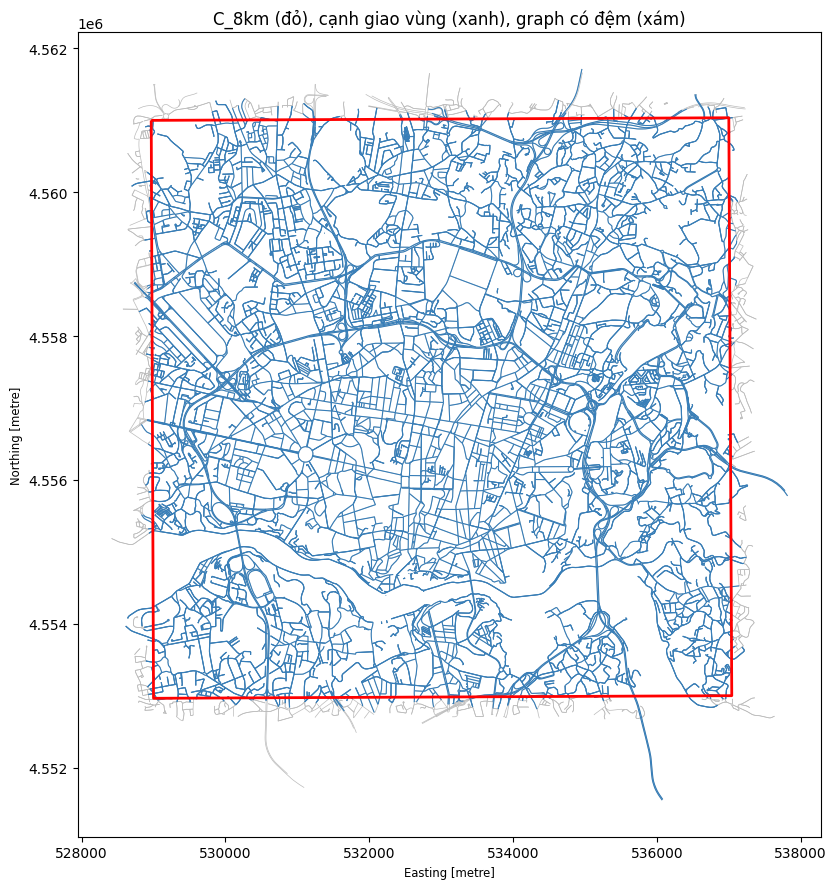

[graph] complete: {'graph_edges_including_buffer': 17739, 'full_edges_inside_region': 15464, 'edges_intersecting_region': 15882, 'graph_nodes': 8400, 'directed_length_inside_region_m': 1430479.796925856, 'weak_components': 29}
region_road_graph: 9.5s; RSS cuối bước=618 MiB


In [6]:
def verified_raw_overpass_source():
    """Prove cache identity and query footprint before rebuilding a larger graph.

    OSMnx 2.1.1 requests an extra 500 m before simplifying/truncating its graph.
    Its raw response can therefore cover more than the saved GraphML snapshot.
    Never infer spatial completeness from the bounding box of returned nodes.
    """
    if not CFG.get("reuse_raw_overpass_cache",True):
        return None
    if VERSIONS["osmnx"]!="2.1.1":
        return None
    from urllib.parse import urlencode
    from shapely.geometry import Polygon, mapping
    from osmnx import _overpass
    original_timeout=ox.settings.requests_timeout
    try:
        for metadata_path in sorted((ROOT/"cache/graphs").glob("*/metadata.json")):
            meta=json.loads(metadata_path.read_text(encoding="utf-8")); source_cfg=meta.get("config",{})
            graph_path=metadata_path.parent/"porto.graphml"
            if source_cfg.get("network_type")!="drive" or source_cfg.get("osmnx")!="2.1.1":
                continue
            if not graph_path.exists() or file_hash(graph_path)!=meta.get("graph_file_sha256"):
                continue
            forward=Transformer.from_crs(4326,source_cfg["metric_crs"],always_xy=True)
            backward=Transformer.from_crs(source_cfg["metric_crs"],4326,always_xy=True)
            original=shapely.transform(box(*source_cfg["bbox"]),forward.transform,interleaved=False).buffer(source_cfg["graph_buffer_m"])
            requested=shapely.transform(original,backward.transform,interleaved=False)
            projected,source_crs=ox.projection.project_geometry(requested)
            query,_=ox.projection.project_geometry(projected.buffer(500),crs=source_crs,to_latlong=True)
            strings=_overpass._make_overpass_polygon_coord_strs(query)
            # Current cached Porto source has one query. Do not silently assume
            # that one response covers a spatially subdivided multi-query area.
            if len(strings)!=1:
                continue
            coords=list(map(float,strings[0].split()))
            footprint=Polygon([(coords[i+1],coords[i]) for i in range(0,len(coords),2)])
            footprint_metric=shapely.transform(footprint,PROJECT.transform,interleaved=False)
            if not footprint_metric.covers(BUFFER_POLYGON):
                continue
            way_filter=_overpass._get_network_filter("drive")
            for timeout in [90,180,300]:
                ox.settings.requests_timeout=timeout
                settings=_overpass._make_overpass_settings()
                query_text=f"{settings};(way{way_filter}(poly:{strings[0]!r});>;);out;"
                for endpoint in ["https://overpass-api.de/api","https://overpass.kumi.systems/api","https://overpass.private.coffee/api"]:
                    url=endpoint+"/interpreter?"+urlencode({"data":query_text})
                    sha1=hashlib.sha1(url.encode("utf-8")).hexdigest()
                    path=ROOT/CFG["source_overpass_cache_dir"]/(sha1+".json")
                    if not path.exists():
                        continue
                    response=json.loads(path.read_text(encoding="utf-8"))
                    if not response.get("elements") or response.get("remark"):
                        continue
                    certificate={"source":"Verified original OSMnx Overpass raw-response cache",
                        "source_metadata":str(metadata_path),"source_query_endpoint":endpoint,
                        "prepared_query_url_sha1":sha1,"response_sha256":file_hash(path),"response_path":str(path),
                        "source_timeout_s":timeout,"source_network_type":"drive",
                        "source_query_polygon_wgs84":mapping(footprint),"source_osmnx_internal_buffer_m":500,
                        "covers_requested_study_and_buffer":True,"downloaded_now":False,
                        "downloaded_utc":meta.get("downloaded_utc"),"osm_base_timestamp":response.get("osm3s",{}).get("timestamp_osm_base"),
                        "historical_snapshot":False,"private_api_checked_for_osmnx":"2.1.1"}
                    return response,footprint,certificate
    finally:
        ox.settings.requests_timeout=original_timeout
    return None


def graph_source():
    if CFG["reuse_existing_graph"]:
        for metadata_path in sorted((ROOT/"cache/graphs").glob("*/metadata.json")):
            meta=json.loads(metadata_path.read_text(encoding="utf-8")); config=meta.get("config",{})
            path=metadata_path.parent/"porto.graphml"
            if not path.exists() or "bbox" not in config or config.get("network_type")!="drive":
                continue
            polygon=shapely.transform(box(*config["bbox"]),PROJECT.transform,interleaved=False).buffer(config["graph_buffer_m"])
            if polygon.covers(BUFFER_POLYGON) and file_hash(path)==meta.get("graph_file_sha256"):
                return path,meta
    return None,None

def load_region_graph():
    source,source_meta=graph_source()
    raw_source=None if source else verified_raw_overpass_source()
    spec={k:CFG[k] for k in ["bbox","graph_buffer_m","metric_crs"]}
    spec.update(network_type="drive",osmnx=VERSIONS["osmnx"],source_graph_sha256=file_hash(source) if source else None,
                raw_response_sha256=raw_source[2]["response_sha256"] if raw_source else None,
                algorithm="verified_raw_cache_or_graph_or_download_v2")
    folder=CACHE/"graphs"/stable_hash(spec)[:20]; folder.mkdir(parents=True,exist_ok=True)
    path=folder/"region.graphml"; meta_path=folder/"metadata.json"
    if path.exists() and meta_path.exists() and not CFG["force_graph"]:
        meta=json.loads(meta_path.read_text(encoding="utf-8"))
        if file_hash(path)!=meta["graph_file_sha256"]:
            raise RuntimeError("Graph cache sai checksum; không dùng snapshot bị thay đổi.")
        graph=ox.load_graphml(path)
    else:
        if source:
            parent=ox.load_graphml(source)
            parent=ox.project_graph(parent,to_crs=CFG["metric_crs"])
            graph=ox.truncate.truncate_graph_polygon(parent,BUFFER_POLYGON,truncate_by_edge=True)
            meta={"source":"OpenStreetMap snapshot already cached; derived with OSMnx truncate_graph_polygon",
                  "source_graph":str(source),"source_metadata":source_meta,"downloaded_now":False,
                  "downloaded_utc":source_meta.get("downloaded_utc"),"historical_snapshot":False}
        elif raw_source:
            response,footprint,certificate=raw_source
            parent=ox.graph._create_graph(iter([response]),bidirectional=False)
            parent=ox.truncate.truncate_graph_polygon(parent,footprint,truncate_by_edge=True)
            parent=ox.simplification.simplify_graph(parent)
            parent=ox.project_graph(parent,to_crs=CFG["metric_crs"])
            graph=ox.truncate.truncate_graph_polygon(parent,BUFFER_POLYGON,truncate_by_edge=True)
            meta=certificate
        else:
            if not CFG["allow_graph_download"]:
                raise RuntimeError("Không có graph cache phủ vùng; allow_graph_download=False.")
            ox.settings.use_cache=True; ox.settings.cache_folder=str(ROOT/"cache/osmnx_http")
            ox.settings.requests_timeout=CFG["graph_timeout_s"]
            query=shapely.transform(BUFFER_POLYGON,UNPROJECT.transform,interleaved=False)
            graph=ox.graph_from_polygon(query,network_type="drive",simplify=True,retain_all=True,truncate_by_edge=True)
            graph=ox.project_graph(graph,to_crs=CFG["metric_crs"])
            meta={"source":"OpenStreetMap contributors via OSMnx/Overpass","downloaded_now":True,
                  "downloaded_utc":datetime.now(timezone.utc).isoformat(),"historical_snapshot":False}
        ox.save_graphml(graph,path)
        meta.update(config=spec,graph_file_sha256=file_hash(path),graph_path=str(path))
        write_json(meta_path,meta)
    edges=make_edge_table(graph)
    edges["inside_offset_ranges"]=[offset_ranges_in_polygon(g,STUDY_POLYGON) for g in edges.geometry]
    edges["length_inside_m"]=[sum(b-a for a,b in rs) for rs in edges.inside_offset_ranges]
    edges["intersects_study"]=edges.length_inside_m.gt(1e-8)
    graph_hash=stable_hash([[r.edge_id,r.geometry.wkb_hex,r.road_class] for r in edges.itertuples()])
    edges["graph_hash"]=graph_hash
    meta["graph_hash"]=graph_hash; write_json(meta_path,meta)
    return graph,edges,graph_hash,meta

GRAPH=EDGES=GRAPH_HASH=GRAPH_METADATA=None
with timed("region_road_graph"):
    try:
        GRAPH,EDGES,GRAPH_HASH,GRAPH_METADATA=load_region_graph()
        # Keep geometries/mapping in GeoParquet; serialize range lists separately in a normal table.
        EDGES.drop(columns="inside_offset_ranges").to_parquet(RUN/"edges.parquet",index=False)
        write_json(RUN/"edge_inside_offset_ranges.json",dict(zip(EDGES.edge_id,EDGES.inside_offset_ranges)))
        write_json(RUN/"graph_metadata.json",GRAPH_METADATA)
        GRAPH_COUNTS={"graph_edges_including_buffer":len(EDGES),"full_edges_inside_region":int(EDGES.in_study.sum()),
            "edges_intersecting_region":int(EDGES.intersects_study.sum()),"graph_nodes":len(GRAPH),
            "directed_length_inside_region_m":float(EDGES.length_inside_m.sum()),
            "weak_components":nx.number_weakly_connected_components(GRAPH)}
        write_json(RUN/"graph_counts.json",GRAPH_COUNTS)
        display(pd.Series(GRAPH_COUNTS,name="value").to_frame())
        fig,ax=plt.subplots(figsize=(10,9))
        EDGES.plot(ax=ax,color="#bbbbbb",linewidth=.5)
        EDGES[EDGES.intersects_study].plot(ax=ax,color="#377eb8",linewidth=.8)
        gpd.GeoSeries([STUDY_POLYGON],crs=CFG["metric_crs"]).boundary.plot(ax=ax,color="red",linewidth=2)
        ax.set_title(f"{CFG['region_name']} (đỏ), cạnh giao vùng (xanh), graph có đệm (xám)")
        ax.set_aspect("equal"); save_figure("01_region_road_graph")
        record_stage("graph","complete",str(GRAPH_COUNTS))
    except Exception as error:
        record_stage("graph","blocked",f"{type(error).__name__}: {error}")

## D. Leuven HMM và QA matching trên vùng đệm

Leuven dùng chuỗi quan sát và trạng thái không phát xạ để đi qua các đoạn đường
giữa hai GPS. Các cạnh được chia thành microedge theo hình học, giữ ánh xạ về cạnh
có hướng gốc và offset mét; đây không phải nearest-edge. API được kiểm tra qua
phiên bản, signature và thử fixture trước khi xử lý dữ liệu thật.

Tách **matcher trả kết quả** khỏi **đoạn đạt QA**. QA kiểm tra độ lệch, tỷ lệ điểm/
khoảng giữ lại, hướng và liên thông, offset, tốc độ quá lớn, detour. Không loại mọi
điểm tốc độ thấp. Matching đánh giá trên đoạn context có đệm; clipping về vùng
nghiên cứu được làm sau đó, tránh coi một cạnh biên hợp lệ là lỗi matching.

Thời gian trên nhiều cạnh giữa hai GPS được phân bổ theo tỷ lệ quãng đường, giả
định tốc độ không đổi trong khoảng 15 giây. Lưu `interval_id`, cờ nội suy và phần
cạnh thực sự đi qua; không coi các mảnh đó là quan sát GPS độc lập. Thời gian từng
cạnh ngắn chưa đủ tin cậy để tự kết luận giảm tốc.

**Xử lý đứng yên mơ hồ:** nếu một interval có quãng đường bằng 0 nhưng đường
khớp gồm nhiều cạnh, phân bổ theo khoảng cách không xác định. Chỉ loại interval
đó với mã `ambiguous_stationary_edge_assignment`; vẫn xét các interval khác theo
QA cấp đoạn. Không nối qua interval đã loại. Khoảng đứng yên khớp rõ một cạnh vẫn
giữ duration và tốc độ 0. Đây là hiệu chỉnh so với lần chạy B, vốn loại cả đoạn
context khi gặp interval mơ hồ; hai lần chạy khác nhau cả vùng và xử lý QA này.

In [7]:
def collapse_parts(parts):
    combined = []
    for edge_id, start_offset, end_offset in parts:
        if end_offset < start_offset-CFG["backward_jitter_m"]:
            raise ValueError("backward_offset")
        end_offset = max(start_offset,end_offset)
        if combined and combined[-1][0] == edge_id and abs(combined[-1][2]-start_offset)<.01:
            combined[-1] = (edge_id,combined[-1][1],end_offset)
        else:
            combined.append((edge_id,float(start_offset),float(end_offset)))
    return combined

class LeuvenAdapter:
    name = "leuven_hmm"
    def __init__(self, edges, cache_dir):
        from leuvenmapmatching.map.inmem import InMemMap
        from leuvenmapmatching.matcher.distance import DistanceMatcher
        self.matcher_class = DistanceMatcher
        graph, self.micro = {}, {}
        node_map = {int(value):index for index,value in enumerate(sorted(set(edges.u)|set(edges.v)))}
        next_node = len(node_map)
        for row in edges.itertuples():
            coordinates = list(row.geometry.coords)
            # Ít nhất 2 microedges: phân biệt song song kể cả cạnh thẳng.
            if len(coordinates)==2:
                middle = row.geometry.interpolate(.5,normalized=True)
                coordinates.insert(1,(middle.x,middle.y))
            dense = [coordinates[0]]
            for a,b in zip(coordinates[:-1],coordinates[1:]):
                distance = np.hypot(b[0]-a[0],b[1]-a[1])
                for fraction in np.linspace(0,1,max(1,int(np.ceil(distance/CFG["microedge_max_m"])))+1)[1:]:
                    dense.append((a[0]+fraction*(b[0]-a[0]),a[1]+fraction*(b[1]-a[1])))
            labels = [node_map[int(row.u)]]
            for _ in dense[1:-1]:
                labels.append(next_node)
                next_node += 1
            labels.append(node_map[int(row.v)])
            offset = 0.0
            for index,(a,b) in enumerate(zip(dense[:-1],dense[1:])):
                length = float(np.hypot(b[0]-a[0],b[1]-a[1]))
                if length<1e-8:
                    raise ValueError("Zero length vertex segment trong road geometry.")
                left,right = labels[index],labels[index+1]
                for node,coordinate in [(left,a),(right,b)]:
                    if node not in graph:
                        graph[node] = ((coordinate[1],coordinate[0]),[])
                graph[left][1].append(right)
                self.micro[(left,right)] = {"edge_id":row.edge_id,"start":offset,"length":length,
                                           "line":LineString([a,b])}
                offset += length
        self.map = InMemMap("porto_projected_directed",graph=graph,use_latlon=False,use_rtree=True,index_edges=True)

    def match(self, points):
        matcher = self.matcher_class(self.map,max_dist=CFG["candidate_radius_m"],
                    max_dist_init=CFG["candidate_radius_m"],obs_noise=CFG["gps_error_m"],
                    dist_noise=CFG["gps_error_m"]*2,min_prob_norm=.001,
                    max_lattice_width=CFG["hmm_lattice_width"],non_emitting_states=True,
                    only_edges=True,avoid_goingback=True)
        matcher.match([(p["y"],p["x"]) for p in points],unique=False)
        lattice = matcher.lattice_best or []
        if lattice and not all(hasattr(lattice[0],name) for name in ["obs","obs_ne","edge_m","dist_obs"]):
            raise RuntimeError("Leuven lattice API không tương thích với adapter.")
        emitting = [(position,state) for position,state in enumerate(lattice) if state.obs_ne==0]
        intervals, matched_points = [], []
        for position,state in emitting:
            index = int(state.obs)
            micro = self.micro[(state.edge_m.l1,state.edge_m.l2)]
            raw = Point(points[index]["x"],points[index]["y"])
            snapped = micro["line"].interpolate(micro["line"].project(raw))
            matched_points.append({"point_index":index,"edge_id":micro["edge_id"],
                                   "matched_x":snapped.x,"matched_y":snapped.y,"error_m":snapped.distance(raw)})
        for (left_position,left),(right_position,right) in zip(emitting[:-1],emitting[1:]):
            i,j = int(left.obs),int(right.obs)
            if j!=i+1:
                continue
            sequence = []
            for state in lattice[left_position:right_position+1]:
                key = (state.edge_m.l1,state.edge_m.l2)
                if not sequence or sequence[-1]!=key:
                    sequence.append(key)
            if any(a[1]!=b[0] for a,b in zip(sequence[:-1],sequence[1:])):
                continue
            parts = []
            for position,key in enumerate(sequence):
                micro = self.micro[key]
                begin,end = 0.0,micro["length"]
                if position==0:
                    begin = micro["line"].project(Point(points[i]["x"],points[i]["y"]))
                if position==len(sequence)-1:
                    end = micro["line"].project(Point(points[j]["x"],points[j]["y"]))
                parts.append((micro["edge_id"],micro["start"]+begin,micro["start"]+end))
            try:
                parts = collapse_parts(parts)
            except ValueError:
                continue
            intervals.append({"i":i,"j":j,"parts":parts,"error_m":max(float(left.dist_obs),float(right.dist_obs))})
        return intervals,matched_points

def interval_pieces(parts, duration_s):
    """Nội suy chỉ theo độ dài; tổng thời gian đúng bằng khoảng GPS."""
    distances = np.array([max(0.0,b-a) for _,a,b in parts])
    if distances.sum()==0:
        if len(parts)!=1:
            raise ValueError("zero_distance_multiple_edges")
        durations = np.array([duration_s],dtype=float)
    else:
        durations = duration_s*distances/distances.sum()
        durations[-1] += duration_s-durations.sum()
    return [(edge,a,b,float(d),float(t)) for (edge,a,b),d,t in zip(parts,distances,durations) if t>1e-10]

def match_subtrajectory(sub, engine, edge_lookup):
    points = sub["points"]
    intervals, snapped = engine.match(points)
    snapped_unique = {int(item["point_index"]):item for item in snapped}
    returned = bool(intervals)
    point_ratio = len(snapped_unique)/len(points)
    mean_error = float(np.mean([p["error_m"] for p in snapped])) if snapped else np.nan
    audits, accepted = [], []
    seen = set()
    for interval in intervals:
        i,j,parts = interval["i"],interval["j"],interval["parts"]
        if (i,j) in seen:
            continue
        seen.add((i,j))
        reason = "accepted"
        dt = points[j]["timestamp"]-points[i]["timestamp"]
        distance = sum(max(0,b-a) for _,a,b in parts)
        straight = float(np.hypot(points[j]["x"]-points[i]["x"],points[j]["y"]-points[i]["y"]))
        if j!=i+1 or points[j]["original_index"]!=points[i]["original_index"]+1 or dt!=CFG["gps_interval_s"]:
            reason = "nonconsecutive_gps"
        elif not parts:
            reason = "empty_path"
        elif distance <= 1e-8 and len(parts) > 1:
            reason = "ambiguous_stationary_edge_assignment"
        elif interval["error_m"]>CFG["max_match_error_m"]:
            reason = "gps_road_error"
        elif any(edge not in edge_lookup for edge,_,_ in parts):
            reason = "unknown_edge"
        elif any(a<-.05 or b>edge_lookup[e].length_m+.05 or b<a for e,a,b in parts):
            reason = "invalid_offset"
        elif any(edge_lookup[a[0]].v!=edge_lookup[b[0]].u for a,b in zip(parts[:-1],parts[1:])):
            reason = "disconnected_path"
        elif distance/dt*3.6>CFG["max_matched_speed_kmh"]:
            reason = "implausible_matched_speed"
        elif distance>CFG["max_detour_ratio"]*max(CFG["detour_floor_m"],straight):
            reason = "excessive_detour"
        audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                       "original_start_index":points[i]["original_index"],"original_end_index":points[j]["original_index"],
                       "gps_duration_s":dt,"matched_distance_m":distance,"raw_chord_m":straight,"status":reason})
        if reason=="accepted":
            accepted.append(interval)
    for i in range(len(points)-1):
        if (i,i+1) not in seen:
            audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                "original_start_index":points[i]["original_index"],"original_end_index":points[i+1]["original_index"],
                "gps_duration_s":points[i+1]["timestamp"]-points[i]["timestamp"],"matched_distance_m":np.nan,
                "raw_chord_m":float(np.hypot(points[i+1]["x"]-points[i]["x"],points[i+1]["y"]-points[i]["y"])),
                "status":"matcher_omitted_interval"})
    accepted.sort(key=lambda item:item["i"])
    retained_ratio = len(accepted)/max(1,len(points)-1)
    quality_ok = (returned and point_ratio>=CFG["min_matched_point_ratio"]
                  and retained_ratio>=CFG["min_retained_interval_ratio"]
                  and mean_error<=CFG["max_mean_match_error_m"])
    rows, run_index, last_j = [], -1, None
    for interval in accepted if quality_ok else []:
        i,j = interval["i"],interval["j"]
        if i!=last_j:
            run_index += 1
        last_j = j
        interval_id = f"{sub['subtrajectory_id']}:{points[i]['original_index']}:{points[j]['original_index']}"
        start = pd.Timestamp(points[i]["timestamp"],unit="s",tz="UTC")
        finish = pd.Timestamp(points[j]["timestamp"],unit="s",tz="UTC")
        allocated = interval_pieces(interval["parts"],(finish-start).total_seconds())
        cursor = start
        for part_index,(edge_id,begin,end,distance,duration) in enumerate(allocated):
            exit_time = finish if part_index==len(allocated)-1 else cursor+pd.Timedelta(seconds=duration)
            exact_duration = (exit_time.value-cursor.value)/1e9
            rows.append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                         "route_id":f"{sub['subtrajectory_id']}:run{run_index}","split":sub["split"],
                         "interval_id":interval_id,"part_index":part_index,"edge_id":edge_id,
                         "entry_offset_m":begin,"exit_offset_m":end,"entry_time":cursor,"exit_time":exit_time,
                         "distance_traversed_m":distance,"duration_s":exact_duration,
                         "speed_kmh":3.6*distance/exact_duration,"match_quality":max(0.0,1-interval["error_m"]/CFG["candidate_radius_m"]),
                         "gps_road_error_m":interval["error_m"],"is_interpolated":len(allocated)>1,
                         "interval_fanout":len(allocated),"original_start_index":points[i]["original_index"],
                         "original_end_index":points[j]["original_index"],"gps_start_time":start,"gps_end_time":finish,
                         "backend":engine.name,"match_status":"analysis_accepted"})
            cursor = exit_time
        assert abs(sum(r["duration_s"] for r in rows[-len(allocated):])-(finish-start).total_seconds())<1e-5
    qa = {"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],"split":sub["split"],
          "n_points":len(points),"n_intervals":len(points)-1,"n_matched_points":len(snapped_unique),
          "n_retained_points":len({i for item in accepted for i in [item["i"],item["j"]]}) if quality_ok else 0,
          "n_accepted_intervals":len(accepted) if quality_ok else 0,"candidate_accepted_intervals":len(accepted),
          "matcher_returned":returned,"analysis_accepted":quality_ok,"mean_error_m":mean_error,
          "matched_point_ratio":point_ratio,"retained_interval_ratio":retained_ratio,
          "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(points[:-1],points[1:])),
          "retained_raw_chord_m":sum(a["raw_chord_m"] for a in audits if a["status"]=="accepted") if quality_ok else 0,
          "backend":engine.name,"error":""}
    for point in snapped_unique.values():
        original = points[point["point_index"]]
        point.update({"trip_id":sub["trip_id"],"subtrajectory_id":sub["subtrajectory_id"],
                      "original_index":original["original_index"],"timestamp":original["timestamp"],
                      "raw_x":original["x"],"raw_y":original["y"],"analysis_accepted":quality_ok})
    return rows,qa,list(snapped_unique.values()),audits

def run_matching(parts_path,engine,edges,matching_key):
    """Independent CPU workers; cache every completed batch and preserve order."""
    folder=CACHE/"matching"/matching_key
    folder.mkdir(parents=True,exist_ok=True)
    backend_name=engine.name
    batches=[]; batch=[]
    with parts_path.open(encoding="utf-8") as handle:
        for line in handle:
            batch.append(json.loads(line))
            if len(batch)>=CFG["matching_batch_size"]:
                batches.append(batch); batch=[]
    if batch:
        batches.append(batch)

    def flush(items,index):
        import sys,types
        prefix=folder/f"batch_{index:05d}"
        paths={name:prefix.with_name(prefix.name+f"_{name}.parquet") for name in ["parts","qa","points","interval_qa"]}
        marker=prefix.with_suffix(".json")
        identity=stable_hash([matching_key,items])
        if marker.exists() and all(p.exists() for p in paths.values()) and not CFG["force_rematch"]:
            if json.loads(marker.read_text(encoding="utf-8"))["identity"]==identity:
                return index,paths,True,psutil.Process().memory_info().rss/2**20
        # Per-process module state keeps Rtree/HMM maps off the pickle boundary.
        module=sys.modules.setdefault("_porto_leuven_process_cache",types.ModuleType("_porto_leuven_process_cache"))
        if getattr(module,"key",None)!=matching_key:
            module.engine=LeuvenAdapter(edges,folder)
            module.lookup={row.edge_id:row for row in edges.itertuples()}
            module.key=matching_key
        groups={name:[] for name in paths}
        for sub in items:
            try:
                rows,qa,snapped,audits=match_subtrajectory(sub,module.engine,module.lookup)
                groups["parts"].extend(rows); groups["qa"].append(qa)
                groups["points"].extend(snapped); groups["interval_qa"].extend(audits)
            except Exception as error:
                groups["qa"].append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                    "split":sub["split"],"n_points":len(sub["points"]),"n_intervals":len(sub["points"])-1,
                    "n_matched_points":0,"n_retained_points":0,"n_accepted_intervals":0,
                    "matcher_returned":False,"analysis_accepted":False,"mean_error_m":np.nan,
                    "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(sub["points"][:-1],sub["points"][1:])),
                    "retained_raw_chord_m":0.,"backend":backend_name,"error":f"{type(error).__name__}: {error}"})
        for name,path in paths.items():
            write_table(pd.DataFrame(groups[name]),path)
        write_json(marker,{"identity":identity,"matching_key":matching_key,"subtrajectories":len(items)})
        return index,paths,False,psutil.Process().memory_info().rss/2**20

    workers=max(1,min(int(CFG.get("matching_workers",1)),len(batches)))
    started=time.perf_counter(); saved={}; completed=0; hits=0; worker_rss=0.
    total_subs=sum(map(len,batches))
    progress_path=RUN/"matching_progress.json"
    write_json(progress_path,{"status":"running","completed_batches":0,"total_batches":len(batches),
        "completed_subtrajectories":0,"total_subtrajectories":total_subs,"workers":workers})
    with parallel_config(backend="loky",inner_max_num_threads=1):
        results=Parallel(n_jobs=workers,return_as="generator_unordered",pre_dispatch=workers*2,max_nbytes=None)(
            delayed(flush)(items,index) for index,items in enumerate(batches))
        for index,paths,cache_hit,rss in results:
            saved[index]=paths; completed+=len(batches[index]); hits+=int(cache_hit); worker_rss=max(worker_rss,rss)
            elapsed=time.perf_counter()-started
            write_json(progress_path,{"status":"running","completed_batches":len(saved),"total_batches":len(batches),
                "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
                "cache_hits":hits,"elapsed_s":elapsed,"max_single_worker_rss_mb":worker_rss})
            if len(saved)%5==0 or len(saved)==len(batches):
                print(f"Matching: {completed}/{total_subs} subtrajectories; batches {len(saved)}/{len(batches)}; "
                      f"elapsed={elapsed:.1f}s; workers={workers}",flush=True)
    outputs={}
    for name in ["parts","qa","points","interval_qa"]:
        frames=[pd.read_parquet(saved[i][name]) for i in sorted(saved)]
        outputs[name]=pd.concat([f for f in frames if not f.empty],ignore_index=True) if any(not f.empty for f in frames) else pd.DataFrame()
    write_json(RUN/"matching_cache.json",{"matching_key":matching_key,"folder":str(folder),"backend":backend_name,
        "workers":workers,"cached_batches":hits,"batch_count":len(batches),"max_single_worker_rss_mb":worker_rss})
    write_json(progress_path,{"status":"complete","completed_batches":len(saved),"total_batches":len(batches),
        "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
        "cache_hits":hits,"elapsed_s":time.perf_counter()-started,"max_single_worker_rss_mb":worker_rss})
    return outputs

## E. Kiểm thử kỹ thuật trước matching thật

Fixture tổng hợp chỉ kiểm tra logic; không trình bày thành kết quả Porto. Kiểm tra
timestamp sau lọc, phần cạnh, đứng yên, ra/vào vùng đệm và matcher chuỗi có hướng.

In [8]:
def run_pilot_tests():
    tests=[]
    def check(name,condition):
        if not condition:
            raise AssertionError(name)
        tests.append({"test":name,"status":"passed","scope":"Synthetic fixture only; not Porto results"})
    original=np.array([0,1,4,5]); ts=1000+15*original
    check("timestamp_uses_original_index",np.array_equal(ts,[1000,1015,1060,1075]))
    check("gap_is_not_renumbered",ts[2]-ts[1]==45)
    allocation=interval_pieces([("a",10.,30.),("b",0.,10.)],15.)
    check("partial_distance_not_full_edge",sum(r[3] for r in allocation)==30.)
    check("duration_allocation_conserved",abs(sum(r[4] for r in allocation)-15)<1e-9)
    stationary=interval_pieces([("a",20.,20.)],15.)
    check("stationary_duration_retained",stationary[0][3]==0 and stationary[0][4]==15)
    ranges=offset_ranges_in_polygon(LineString([(0,0),(100,0)]),box(20,-5,70,5))
    check("boundary_partial_offsets",np.allclose(ranges,[(20,70)]))
    check("region_exit_reentry_ranges",len(offset_ranges_in_polygon(LineString([(0,0),(100,0),(0,1)]),box(20,-5,70,5)))==2)
    cap=pd.Series([1,9,10],index=["d1","d2","d3"]); q=fair_quotas(cap,12,313)
    check("sampling_quota_capacity_and_budget",q.sum()==12 and q.le(cap).all())
    coords=[[(0,0),(100,0)],[(100,0),(200,0)]]
    fixture=gpd.GeoDataFrame([{"edge_id":"a","u":0,"v":1,"key":0,"length_m":100.,"geometry":LineString(coords[0]),"in_study":True},
                              {"edge_id":"b","u":1,"v":2,"key":0,"length_m":100.,"geometry":LineString(coords[1]),"in_study":True}],crs=CFG["metric_crs"])
    engine=LeuvenAdapter(fixture,CACHE/"fixture")
    points=[{"x":float(x),"y":1.,"original_index":i,"timestamp":1000+15*i} for i,x in enumerate([20,40,60,80,110,140,180])]
    sub={"trip_id":"fixture","taxi_id":"fixture_taxi","subtrajectory_id":"fixture:0","split":"fixture","points":points}
    rows,qa,_,audits=match_subtrajectory(sub,engine,{r.edge_id:r for r in fixture.itertuples()})
    check("real_hmm_api_and_directed_sequence",qa["analysis_accepted"] and {r["edge_id"] for r in rows}=={"a","b"})
    check("hmm_partial_offset",abs(rows[0]["entry_offset_m"]-20)<2)
    check("hmm_interval_time_conservation",abs(sum(r["duration_s"] for r in rows)-90)<1e-5)
    class ControlledStationaryMatcher:
        name="controlled_fixture_only"
        def match(self,points):
            intervals=[{"i":0,"j":1,"parts":[("a",20.,40.)],"error_m":0.},
                       {"i":1,"j":2,"parts":[("a",40.,40.),("b",0.,0.)],"error_m":0.},
                       {"i":2,"j":3,"parts":[("a",40.,60.)],"error_m":0.}]
            snapped=[{"point_index":i,"edge_id":"a","matched_x":p["x"],"matched_y":p["y"],"error_m":0.} for i,p in enumerate(points)]
            return intervals,snapped
    controlled=[{"x":float(x),"y":0.,"original_index":i,"timestamp":1000+15*i} for i,x in enumerate([20,40,40,60])]
    sub={"trip_id":"stationary_fixture","taxi_id":"fixture","subtrajectory_id":"stationary_fixture:s","split":"fixture","points":controlled}
    rows,qa,_,audits=match_subtrajectory(sub,ControlledStationaryMatcher(),{r.edge_id:r for r in fixture.itertuples()})
    check("ambiguous_stationary_rejects_only_interval",qa["analysis_accepted"] and len(rows)==2 and sum(r["duration_s"] for r in rows)==30.)
    check("ambiguous_stationary_gap_not_bridged",len({r["route_id"] for r in rows})==2 and sum(a["status"]=="ambiguous_stationary_edge_assignment" for a in audits)==1)
    return pd.DataFrame(tests)

with timed("technical_fixture_tests"):
    TESTS=run_pilot_tests(); write_table(TESTS,RUN/"technical_tests.parquet",csv=True)
    display(TESTS)

,test,status,scope
0,timestamp_uses_original_index,passed,Synthetic fixture only; not Porto results
1,gap_is_not_renumbered,passed,Synthetic fixture only; not Porto results
2,partial_distance_not_full_edge,passed,Synthetic fixture only; not Porto results
3,duration_allocation_conserved,passed,Synthetic fixture only; not Porto results
4,stationary_duration_retained,passed,Synthetic fixture only; not Porto results
5,boundary_partial_offsets,passed,Synthetic fixture only; not Porto results
6,region_exit_reentry_ranges,passed,Synthetic fixture only; not Porto results
7,sampling_quota_capacity_and_budget,passed,Synthetic fixture only; not Porto results
8,real_hmm_api_and_directed_sequence,passed,Synthetic fixture only; not Porto results
9,hmm_partial_offset,passed,Synthetic fixture only; not Porto results


technical_fixture_tests: 0.0s; RSS cuối bước=619 MiB


In [9]:
MATCHED_PARTS=MATCH_QA=MATCH_POINTS=INTERVAL_QA=None
if GRAPH is not None and SUBS:
    with timed("map_matching_region_sample"):
        try:
            MATCHER=LeuvenAdapter(EDGES,CACHE/"matcher")
            MATCHING_KEY=stable_hash([SOURCE_HASH,GRAPH_HASH,CODE_HASH,CFG,VERSIONS,file_hash(PARTS_PATH),MATCHER.name])[:24]
            matches=run_matching(PARTS_PATH,MATCHER,EDGES,MATCHING_KEY)
            MATCHED_PARTS,MATCH_QA,MATCH_POINTS,INTERVAL_QA=[matches[n] for n in ["parts","qa","points","interval_qa"]]
            for name,frame in matches.items():
                write_table(frame,RUN/f"matching_{name}.parquet",csv=name in ["qa","interval_qa"])
            for col in ["n_matched_points","n_retained_points","n_accepted_intervals","retained_raw_chord_m"]:
                MATCH_QA[col]=MATCH_QA[col].fillna(0)
            MATCH_SUMMARY={"selected_trips":len(SELECTED),"attempted_trips":MATCH_QA.trip_id.nunique(),
                "attempted_subtrajectories":len(MATCH_QA),"matcher_returned_subtrajectories":int(MATCH_QA.matcher_returned.sum()),
                "qa_accepted_subtrajectories":int(MATCH_QA.analysis_accepted.sum()),
                "qa_accepted_trips_context":MATCH_QA.loc[MATCH_QA.analysis_accepted,"trip_id"].nunique(),
                "matched_point_fraction":float(MATCH_QA.n_matched_points.sum()/max(1,MATCH_QA.n_points.sum())),
                "qa_retained_point_fraction":float(MATCH_QA.n_retained_points.sum()/max(1,MATCH_QA.n_points.sum())),
                "qa_retained_interval_fraction":float(MATCH_QA.n_accepted_intervals.sum()/max(1,MATCH_QA.n_intervals.sum())),
                "qa_retained_raw_chord_fraction":float(MATCH_QA.retained_raw_chord_m.sum()/max(1e-9,MATCH_QA.raw_distance_m.sum())),
                "mean_snap_error_m":float(MATCH_POINTS.error_m.mean()) if not MATCH_POINTS.empty else None,
                "backend":MATCHER.name,"point_denominator":"context subtrajectory points; chunk boundary points may repeat"}
            write_json(RUN/"matching_metrics.json",MATCH_SUMMARY)
            display(pd.Series(MATCH_SUMMARY,name="value").to_frame())
            record_stage("matching","complete" if not MATCHED_PARTS.empty else "blocked",
                         f"{len(MATCHED_PARTS)} partial-edge pieces; xem matcher_returned và analysis_accepted riêng")
        except Exception as error:
            record_stage("matching","blocked",f"{type(error).__name__}: {error}")
else:
    record_stage("matching","blocked","Thiếu graph hoặc không có đoạn GPS đủ điểm; không tạo kết quả giả.")

Matching: 125/10838 subtrajectories; batches 5/434; elapsed=1.0s; workers=3


Matching: 250/10838 subtrajectories; batches 10/434; elapsed=1.2s; workers=3


Matching: 375/10838 subtrajectories; batches 15/434; elapsed=1.4s; workers=3


Matching: 500/10838 subtrajectories; batches 20/434; elapsed=1.6s; workers=3


Matching: 625/10838 subtrajectories; batches 25/434; elapsed=1.8s; workers=3


...

Matching: 10625/10838 subtrajectories; batches 425/434; elapsed=890.3s; workers=3


Matching: 10750/10838 subtrajectories; batches 430/434; elapsed=906.4s; workers=3


Matching: 10838/10838 subtrajectories; batches 434/434; elapsed=916.8s; workers=3


,value
selected_trips,9501
attempted_trips,9489
attempted_subtrajectories,10838
matcher_returned_subtrajectories,10583
qa_accepted_subtrajectories,7412
qa_accepted_trips_context,6557
matched_point_fraction,0.710098
qa_retained_point_fraction,0.596294
qa_retained_interval_fraction,0.592095
qa_retained_raw_chord_fraction,0.565328


[matching] complete: 430329 partial-edge pieces; xem matcher_returned và analysis_accepted riêng
map_matching_region_sample: 926.0s; RSS cuối bước=959 MiB


## F. Giữ phần cạnh trong vùng đã chọn, traversal và coverage theo giờ

Clipping dùng offset thật của từng mảnh matched edge. Nếu taxi chỉ đi một phần cạnh,
không lấy chiều dài toàn cạnh. Vào/ra bbox trong cùng khoảng GPS được đánh dấu nội
suy theo giả định tốc độ không đổi; rời vùng rồi quay lại tạo visit/route mới.
Thời gian UTC không thay đổi khi đổi nhãn ngày/giờ Lisbon. Lần đi lại cùng cạnh sau
khi đã qua cạnh khác được cấp traversal mới; khoảng GPS gốc giữ ID để đếm hỗ trợ.

Coverage báo cả số cạnh và chiều dài: (a) chiều dài các cạnh có quan sát, (b) hợp
các khoảng offset thực sự đã đi qua. Hai đại lượng này khác nhau. Khung giờ có thể
được cắt qua nhiều bin theo thời gian của từng phần, không gán cả chuyến vào giờ xuất phát.

In [10]:
def clip_parts_to_region(parts,edges):
    lookup={r.edge_id:r for r in edges.itertuples()}; rows=[]
    for original in parts.to_dict("records"):
        edge=lookup[original["edge_id"]]; a=original["entry_offset_m"]; b=original["exit_offset_m"]
        if b-a<=1e-8:
            intersections=[(a,b)] if STUDY_POLYGON.covers(edge.geometry.interpolate(a)) else []
        else:
            intersections=[(max(a,left),min(b,right)) for left,right in edge.inside_offset_ranges if min(b,right)>max(a,left)+1e-8]
        for j,(left,right) in enumerate(intersections):
            row=original.copy(); duration=original["duration_s"]
            f0=(left-a)/(b-a) if b>a else 0.; f1=(right-a)/(b-a) if b>a else 1.
            start=pd.Timestamp(original["entry_time"]); finish=pd.Timestamp(original["exit_time"])
            row.update(entry_offset_m=left,exit_offset_m=right,distance_traversed_m=right-left,
                entry_time=start+pd.Timedelta(seconds=duration*f0),exit_time=finish if f1==1 else start+pd.Timedelta(seconds=duration*f1),
                boundary_interpolated=f0>1e-8 or f1<1-1e-8,is_interpolated=bool(original["is_interpolated"] or f0>1e-8 or f1<1-1e-8),
                region_piece_index=j,buffer_route_id=original["route_id"],graph_hash=GRAPH_HASH,
                time_allocation="distance_proportional_within_original_gps_interval")
            row["duration_s"]=(row["exit_time"].value-row["entry_time"].value)/1e9
            if row["duration_s"]<=0:
                continue
            row["speed_kmh"]=3.6*row["distance_traversed_m"]/row["duration_s"]
            rows.append(row)
    if not rows:
        return pd.DataFrame()
    frame=pd.DataFrame(rows).sort_values(["subtrajectory_id","entry_time","part_index","region_piece_index"]).reset_index(drop=True)
    previous=frame.shift()
    continuous=(frame.subtrajectory_id.eq(previous.subtrajectory_id)&frame.buffer_route_id.eq(previous.buffer_route_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5))
    frame["visit_number"]=(~continuous).cumsum()
    frame["route_id"]=frame.subtrajectory_id+":region_visit"+frame.visit_number.astype(str)
    return frame

def build_traversals(parts):
    frame=parts.sort_values(["route_id","entry_time","part_index"]).copy(); previous=frame.shift()
    continuous=(frame.route_id.eq(previous.route_id)&frame.edge_id.eq(previous.edge_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5)
                &((frame.entry_offset_m-previous.exit_offset_m).abs()<.05))
    frame["traversal_number"]=(~continuous).cumsum(); rows=[]
    for number,group in frame.groupby("traversal_number",sort=False):
        first,last=group.iloc[0],group.iloc[-1]
        distance=group.distance_traversed_m.sum(); duration=group.duration_s.sum()
        rows.append({"trip_id":first.trip_id,"taxi_id":first.taxi_id,"subtrajectory_id":first.subtrajectory_id,
            "route_id":first.route_id,"traversal_id":f"{first.route_id}:t{number}","edge_id":first.edge_id,
            "entry_time":first.entry_time,"exit_time":last.exit_time,"entry_offset_m":first.entry_offset_m,
            "exit_offset_m":last.exit_offset_m,"distance_traversed_m":distance,"duration_s":duration,
            "speed_kmh":3.6*distance/duration,"match_quality":group.match_quality.min(),
            "is_interpolated":bool(group.is_interpolated.any()),"boundary_interpolated":bool(group.boundary_interpolated.any()),
            "interval_ids":sorted(set(group.interval_id)),"n_independent_intervals":group.interval_id.nunique(),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(rows)

def time_fragments(start,end,distance):
    start,end=pd.Timestamp(start),pd.Timestamp(end); cursor=start
    total=(end.value-start.value)/1e9
    while cursor<end:
        boundary=cursor.floor(f"{CFG['time_bin_hours']}h")+pd.Timedelta(hours=CFG["time_bin_hours"])
        finish=min(end,boundary); local=cursor.tz_convert(CFG["timezone"])
        duration=(finish.value-cursor.value)/1e9
        yield {"date":local.strftime("%Y-%m-%d"),"day_group":"weekday" if local.weekday()<5 else "weekend",
               "slot":local.hour//CFG["time_bin_hours"],"distance_m":distance*duration/total,"duration_s":duration}
        cursor=finish

def edge_time_coverage(parts):
    rows=[]
    for r in parts.itertuples():
        for fragment in time_fragments(r.entry_time,r.exit_time,r.distance_traversed_m):
            rows.append({"edge_id":r.edge_id,"trip_id":r.trip_id,"taxi_id":r.taxi_id,"interval_id":r.interval_id,**fragment})
    fragments=pd.DataFrame(rows)
    aggregate=fragments.groupby(["edge_id","day_group","slot"],as_index=False).agg(
        n_trips=("trip_id","nunique"),n_taxis=("taxi_id","nunique"),n_days=("date","nunique"),
        n_independent_intervals=("interval_id","nunique"),distance_m=("distance_m","sum"),duration_s=("duration_s","sum"))
    aggregate["sufficient"]=aggregate.n_trips.ge(CFG["coverage_min_trips"])&aggregate.n_taxis.ge(CFG["coverage_min_taxis"])&aggregate.n_days.ge(CFG["coverage_min_days"])
    return aggregate

def union_length(ranges):
    merged=[]
    for a,b in sorted(ranges):
        if merged and a<=merged[-1][1]+1e-8:
            merged[-1]=(merged[-1][0],max(b,merged[-1][1]))
        else:
            merged.append((a,b))
    return sum(b-a for a,b in merged)

REGION_PARTS=TRAVERSALS=EDGE_TIME=None
if MATCHED_PARTS is not None and not MATCHED_PARTS.empty:
    with timed("region_clipping_and_coverage"):
        REGION_PARTS=clip_parts_to_region(MATCHED_PARTS,EDGES)
        if REGION_PARTS.empty:
            record_stage("region_observations","blocked","Không còn matched parts bên trong vùng.")
        else:
            TRAVERSALS=build_traversals(REGION_PARTS); EDGE_TIME=edge_time_coverage(REGION_PARTS)
            write_table(REGION_PARTS,RUN/"region_matching_parts.parquet")
            write_table(TRAVERSALS,RUN/"edge_traversals.parquet")
            write_table(EDGE_TIME,RUN/"edge_time_coverage.parquet",csv=True)
            conserved=MATCHED_PARTS.groupby("interval_id").agg(allocated_s=("duration_s","sum"),gps_start=("gps_start_time","first"),gps_end=("gps_end_time","first"))
            conserved["gps_duration_s"]=(conserved.gps_end-conserved.gps_start).dt.total_seconds()
            conserved["absolute_error_s"]=(conserved.allocated_s-conserved.gps_duration_s).abs()
            retained=REGION_PARTS.groupby("interval_id").duration_s.sum()
            assert conserved.absolute_error_s.max()<1e-5
            assert retained.le(conserved.loc[retained.index,"allocated_s"]+1e-5).all()
            assert np.allclose(TRAVERSALS.distance_traversed_m.sum(),REGION_PARTS.distance_traversed_m.sum())
            assert np.allclose(TRAVERSALS.duration_s.sum(),REGION_PARTS.duration_s.sum())
            write_table(conserved.reset_index(),RUN/"interval_time_conservation.parquet",csv=True)
            inside_edges=EDGES[EDGES.intersects_study].copy()
            observed=set(REGION_PARTS.edge_id); lengths=inside_edges.set_index("edge_id").length_inside_m
            exact_length=sum(union_length(list(zip(g.entry_offset_m,g.exit_offset_m))) for _,g in REGION_PARTS.groupby("edge_id"))
            slots=2*(24//CFG["time_bin_hours"]); denominator=len(inside_edges)*slots
            COVERAGE={"region_edges_positive_length":len(inside_edges),"observed_edges_after_qa":len(observed),
                "observed_edge_fraction":len(observed)/len(inside_edges),
                "directed_length_inside_region_m":float(lengths.sum()),
                "length_of_observed_edges_inside_m":float(lengths.loc[list(observed)].sum()),
                "edge_length_weighted_coverage":float(lengths.loc[list(observed)].sum()/lengths.sum()),
                "observed_partial_length_union_m":float(exact_length),"partial_length_union_fraction":float(exact_length/lengths.sum()),
                "observed_edge_time_slots":len(EDGE_TIME),"possible_edge_time_slots":denominator,
                "observed_edge_time_fraction":len(EDGE_TIME)/denominator,
                "supported_edge_time_slots":int(EDGE_TIME.sufficient.sum()),
                "trips_with_qa_observations_inside":REGION_PARTS.trip_id.nunique(),
                "selected_trip_coverage_fraction":REGION_PARTS.trip_id.nunique()/len(SELECTED),
                "region_traversals":len(TRAVERSALS),"max_interval_time_error_s":float(conserved.absolute_error_s.max()),
                "support_thresholds":{"trips":CFG["coverage_min_trips"],"taxis":CFG["coverage_min_taxis"],"days":CFG["coverage_min_days"]}}
            write_json(RUN/"coverage_metrics.json",COVERAGE)
            display(pd.Series(COVERAGE,name="value").to_frame())
            record_stage("region_observations","complete",f"{len(TRAVERSALS)} traversals, {len(observed)} cạnh có quan sát đạt QA trong vùng")

,value
region_edges_positive_length,15882
observed_edges_after_qa,7539
observed_edge_fraction,0.474688
directed_length_inside_region_m,1430479.796926
length_of_observed_edges_inside_m,761523.403451
edge_length_weighted_coverage,0.532355
observed_partial_length_union_m,732785.504205
partial_length_union_fraction,0.512266
observed_edge_time_slots,71086
possible_edge_time_slots,762336


[region_observations] complete: 213448 traversals, 7539 cạnh có quan sát đạt QA trong vùng
region_clipping_and_coverage: 133.9s; RSS cuối bước=1359 MiB


## G. Kiểm tra trực quan và giải thích thất bại

Hiển thị cả đoạn đạt QA và đoạn không đạt nếu có. Đường xám là mạng đường, đen là
GPS đã làm sạch, đỏ là các phần cạnh matcher suy ra; màu đỏ không phải mức ùn tắc.
Lỗi có thể do GPS, mạng đường khác năm 2013, thiếu đường OSM, giới hạn HMM/context
hoặc ngưỡng QA. Không tự gán nguyên nhân khi chưa xem từng trường hợp.

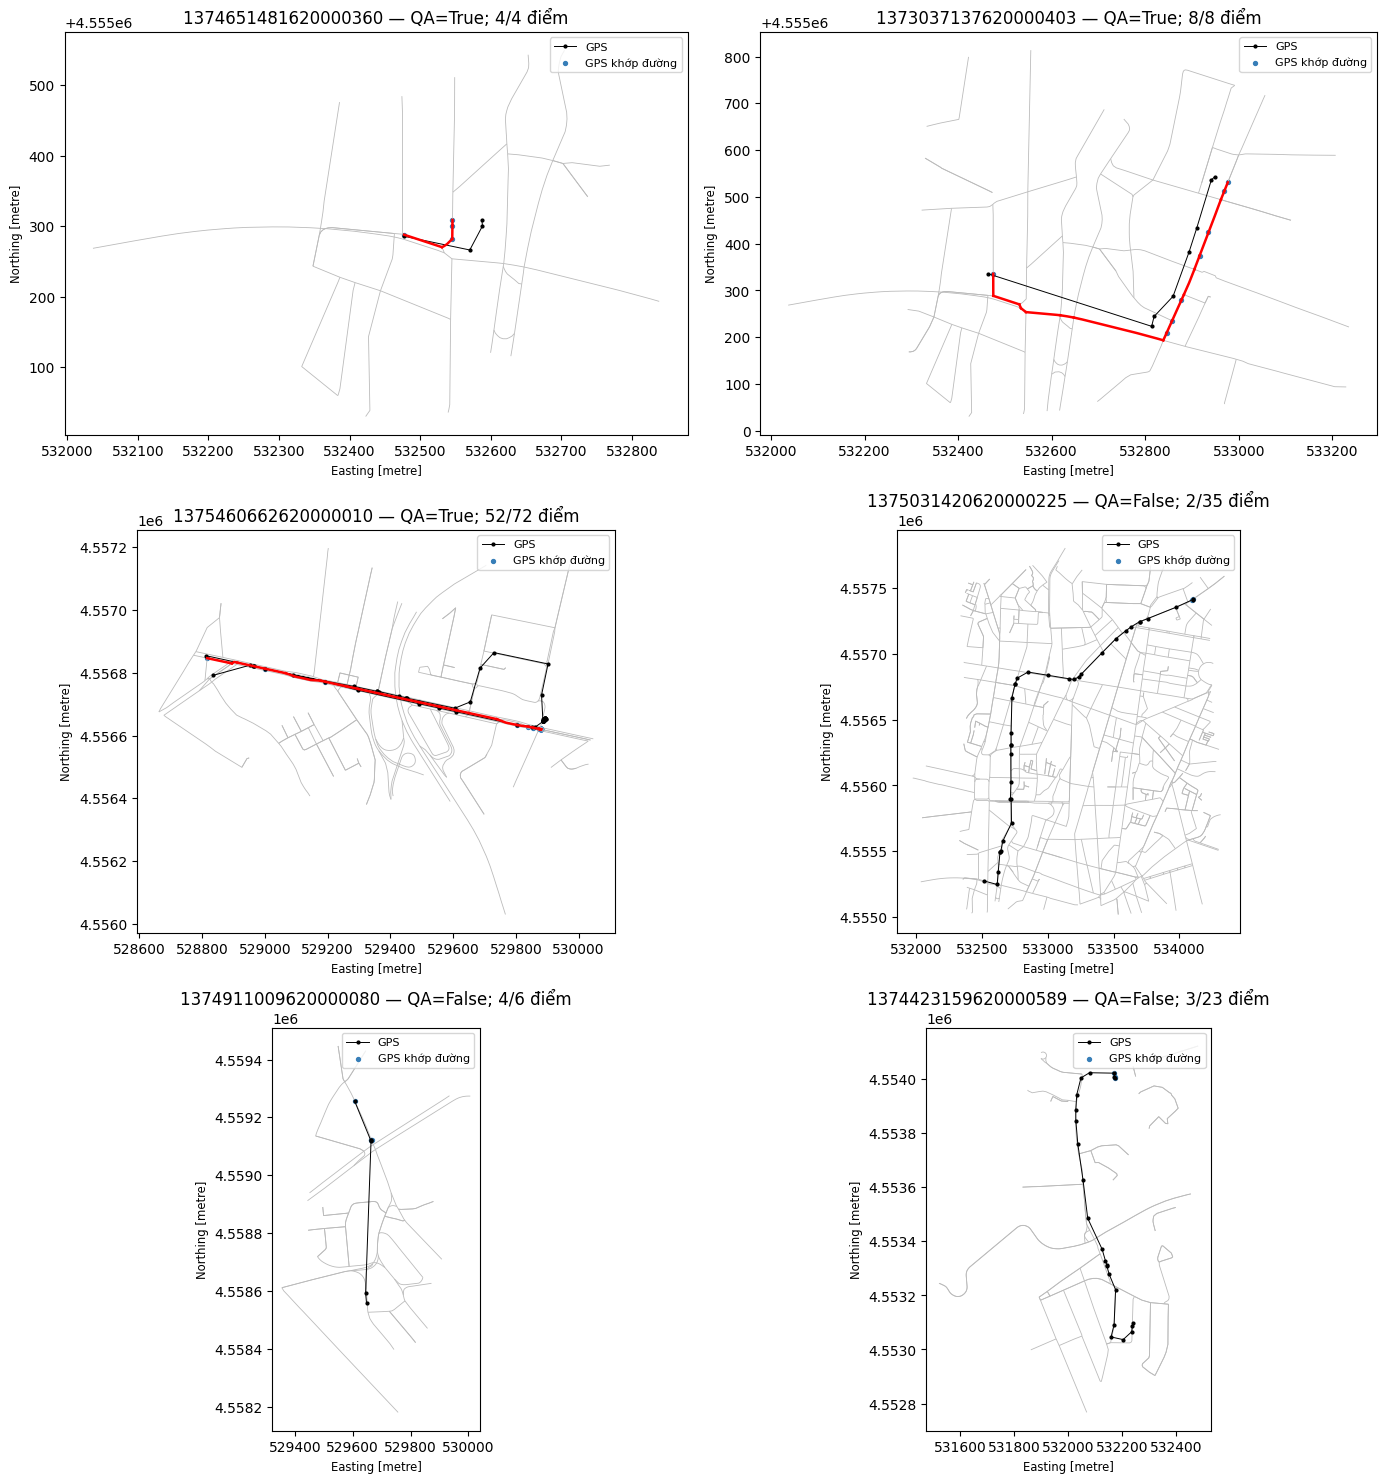

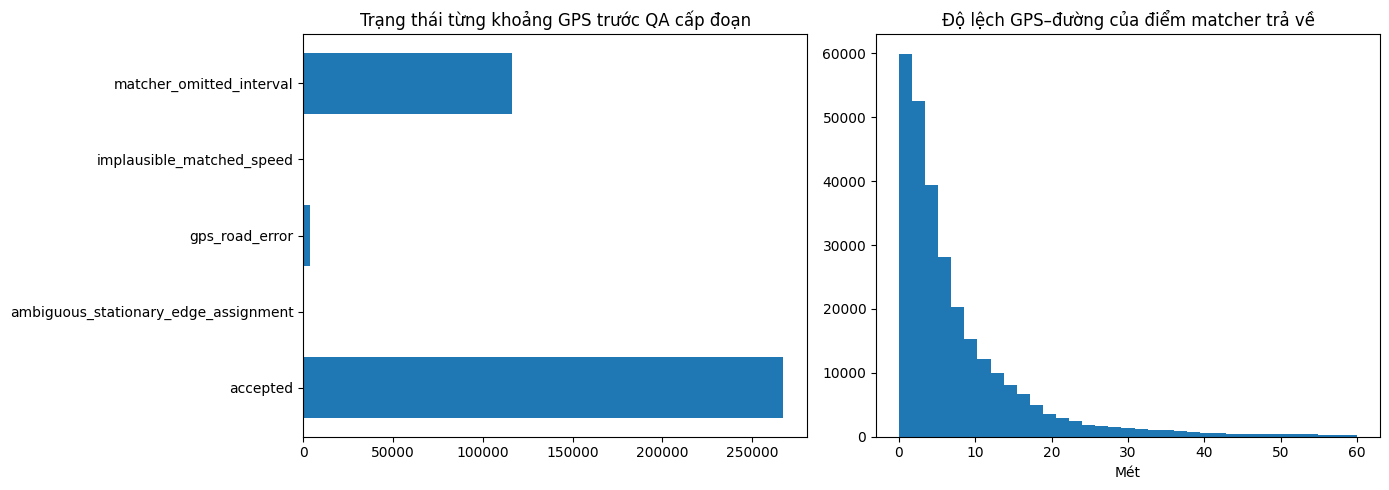

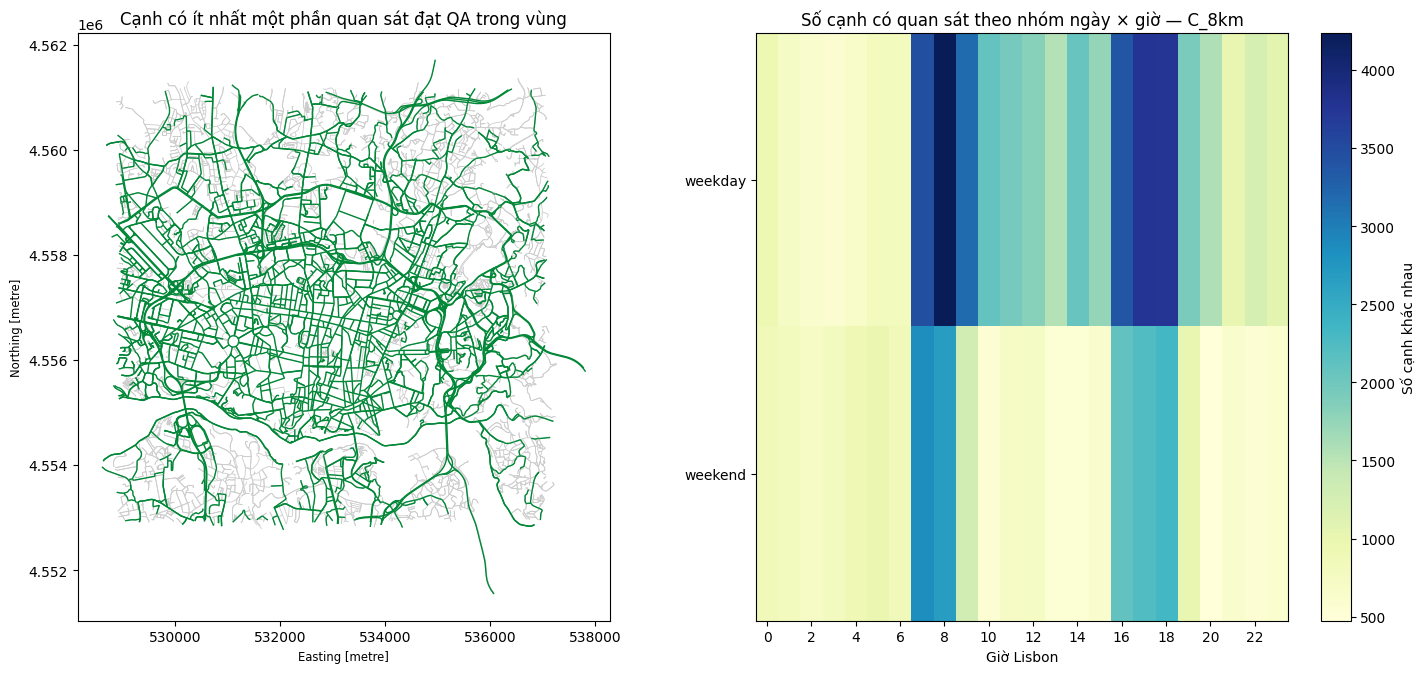

In [11]:
if MATCH_QA is not None and not MATCH_QA.empty:
    qa=MATCH_QA.copy()
    chosen=[]
    for accepted in [True,False]:
        rows=qa[qa.analysis_accepted.eq(accepted)].sort_values(["mean_error_m","subtrajectory_id"],ascending=[not accepted,True])
        chosen.extend(rows.head(max(1,CFG["qa_plot_subtrajectories"]//2)).subtrajectory_id.tolist())
    lookup={s["subtrajectory_id"]:s for s in SUBS}; edge_lookup=EDGES.set_index("edge_id")
    n=len(chosen)
    fig,axes=plt.subplots(math.ceil(n/2),2,figsize=(14,5*math.ceil(n/2)),squeeze=False)
    for ax,sid in zip(axes.flat,chosen):
        sub=lookup[sid]; raw=pd.DataFrame(sub["points"])
        extent=box(raw.x.min()-120,raw.y.min()-120,raw.x.max()+120,raw.y.max()+120)
        local=EDGES[EDGES.geometry.intersects(extent)]
        local.plot(ax=ax,color="#bbb",linewidth=.6)
        ax.plot(raw.x,raw.y,"ko-",markersize=2,linewidth=.7,label="GPS")
        points=MATCH_POINTS[MATCH_POINTS.subtrajectory_id.eq(sid)] if not MATCH_POINTS.empty else pd.DataFrame()
        if not points.empty:
            ax.scatter(points.matched_x,points.matched_y,s=8,color="#377eb8",label="GPS khớp đường")
        parts=MATCHED_PARTS[MATCHED_PARTS.subtrajectory_id.eq(sid)] if not MATCHED_PARTS.empty else pd.DataFrame()
        for row in parts.itertuples():
            line=substring(edge_lookup.loc[row.edge_id,"geometry"],row.entry_offset_m,row.exit_offset_m)
            if isinstance(line,LineString):
                x,y=line.xy; ax.plot(x,y,color="red",linewidth=1.8)
        info=qa[qa.subtrajectory_id.eq(sid)].iloc[0]
        ax.set_title(f"{sub['trip_id']} — QA={bool(info.analysis_accepted)}; {info.n_matched_points}/{info.n_points} điểm")
        ax.set_aspect("equal"); ax.legend(fontsize=8)
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    save_figure("02_matching_success_failure_examples")
    if INTERVAL_QA is not None and not INTERVAL_QA.empty:
        reasons=INTERVAL_QA.groupby("status",as_index=False).size().rename(columns={"size":"n_intervals"})
        write_table(reasons,RUN/"interval_qa_reasons.parquet",csv=True)
        fig,axes=plt.subplots(1,2,figsize=(14,5))
        axes[0].barh(reasons.status,reasons.n_intervals); axes[0].set_title("Trạng thái từng khoảng GPS trước QA cấp đoạn")
        errors=MATCH_POINTS.error_m if MATCH_POINTS is not None and not MATCH_POINTS.empty else pd.Series(dtype=float)
        axes[1].hist(errors,bins=35); axes[1].set(title="Độ lệch GPS–đường của điểm matcher trả về",xlabel="Mét")
        save_figure("03_matching_qa")
if REGION_PARTS is not None and not REGION_PARTS.empty:
    observed=set(REGION_PARTS.edge_id)
    fig,axes=plt.subplots(1,2,figsize=(15,7))
    EDGES[EDGES.intersects_study].plot(ax=axes[0],color="#ccc",linewidth=.6)
    EDGES[EDGES.edge_id.isin(observed)].plot(ax=axes[0],color="#008837",linewidth=1.)
    axes[0].set_title("Cạnh có ít nhất một phần quan sát đạt QA trong vùng")
    axes[0].set_aspect("equal")
    hourly=EDGE_TIME.groupby(["day_group","slot"]).edge_id.nunique().unstack("slot").reindex(["weekday","weekend"]).reindex(columns=range(24//CFG["time_bin_hours"])).fillna(0)
    image=axes[1].imshow(hourly.to_numpy(),aspect="auto",cmap="YlGnBu")
    axes[1].set(yticks=[0,1],yticklabels=hourly.index,xticks=range(0,len(hourly.columns),2),
                xticklabels=[x*CFG["time_bin_hours"] for x in range(0,len(hourly.columns),2)],xlabel="Giờ Lisbon",
                title=f"Số cạnh có quan sát theo nhóm ngày × giờ — {CFG['region_name']}")
    fig.colorbar(image,ax=axes[1],label="Số cạnh khác nhau")
    save_figure("04_observed_edges_and_time_coverage")

## H. Kết quả, cách chạy lại và bước sau

- `graph_counts.json`: phân biệt graph có đệm / cạnh nằm trọn / cạnh giao vùng.
- `matching_metrics.json`: kết quả matcher và QA trên context, không phải nhãn đúng/sai độc lập.
- `coverage_metrics.json`: cạnh và chiều dài có quan sát đạt QA thực sự trong vùng.
- Parquet lưu GPS mẫu trong vùng đã chọn, QA, matched pieces, traversal, interval gốc và coverage để tái sử dụng.
- **Tất cả CSV** ở `outputs/csv/region_pilot/<run_key>/`; biểu đồ ở `figures/`.
- Cache matching gắn với dữ liệu GPS, bbox, buffer, graph hash, phiên bản backend, code và ngưỡng.
  Chạy lại cùng cấu hình dùng cache; tăng mẫu hoặc đổi vùng tạo key khác.
- Matching chạy theo batch trên tối đa `matching_workers` tiến trình CPU độc lập;
  mỗi tiến trình có HMM/Rtree riêng, giới hạn luồng thư viện số bằng 1. Batch hoàn tất
  được lưu ngay; `matching_progress.json` ghi tiến độ để theo dõi hoặc tiếp tục sau gián đoạn.
- Sau khi xem QA và coverage mới cân nhắc tăng mẫu, kiểm tra thời gian trên corridor,
  chọn dữ liệu train/validation/test và chạy các baseline/mô hình trên notebook riêng.
  Chưa kết luận lợi ích định tuyến hay mức ùn tắc từ pilot.

## Tài liệu tham khảo

- Dataset [Kaggle ECML/PKDD 15 Taxi Trajectory Prediction I](https://www.kaggle.com/competitions/pkdd-15-predict-taxi-service-trajectory-i/data).
- `porto_region_eda.ipynb`: mẫu GPS, timestamp, kết quả EDA và ba vùng ứng viên; dùng giai đoạn train đã khảo sát.
- `porto_trajectory_mining.ipynb`: tham khảo và tái sử dụng các hàm matching/QA đã kiểm thử; notebook này chứa đầy đủ code, không import notebook cũ khi chạy.
- [OSMnx User Reference](https://osmnx.readthedocs.io/en/stable/user-reference.html): graph_from_polygon, project_graph, truncate_graph_polygon, save/load_graphml.
- [OpenStreetMap contributors](https://www.openstreetmap.org/copyright): nguồn mạng đường và điều kiện ghi công.
- [Leuven MapMatching](https://leuvenmapmatching.readthedocs.io/en/stable/), [InMemMap API/source](https://leuvenmapmatching.readthedocs.io/en/latest/_modules/leuvenmapmatching/map/inmem.html): HMM và tọa độ `(y,x)` khi use_latlon=False.
- [pandas](https://pandas.pydata.org/docs/), [GeoPandas](https://geopandas.org/en/stable/docs.html),
  [Shapely](https://shapely.readthedocs.io/en/stable/), [pyproj](https://pyproj4.github.io/pyproj/stable/),
  [NetworkX](https://networkx.org/documentation/stable/), [Matplotlib](https://matplotlib.org/stable/),
  [NumPy](https://numpy.org/doc/stable/), [PyArrow](https://arrow.apache.org/docs/python/),
  [psutil](https://psutil.readthedocs.io/), [Rtree](https://rtree.readthedocs.io/en/stable/): thư viện thực sự được dùng.
- [joblib Parallel](https://joblib.readthedocs.io/en/stable/generated/joblib.Parallel.html):
  loky/cloudpickle cho hàm notebook trên Windows, kết quả trả theo batch và giới hạn số tiến trình.

In [12]:
write_json(RUN/"manifest.json",{"config":CFG,"code_hash":CODE_HASH,"source_hash":SOURCE_HASH,"graph_hash":GRAPH_HASH,
    "seed":CFG["seed"],"packages":VERSIONS,"scope":"Existing EDA sample only; no traffic conclusion or model benchmark",
    "stages":STAGES,"runtime":RUNTIME})
write_json(OUTPUT/"latest_run.json",{"folder":str(RUN),"run_key":RUN_KEY,"stages":STAGES})
display(pd.DataFrame(STAGES).T)
print("Đã lưu kết quả tại:",RUN)
print("CSV tại:",ROOT/CFG["csv_dir"]/"region_pilot"/RUN_KEY)

,status,detail
sample,complete,9501/9501 chuyến đủ điều kiện trong mẫu EDA; 1...
graph,complete,"{'graph_edges_including_buffer': 17739, 'full_..."
matching,complete,430329 partial-edge pieces; xem matcher_return...
region_observations,complete,"213448 traversals, 7539 cạnh có quan sát đạt Q..."


Đã lưu kết quả tại: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_pilot\8946a3b89ff42fa9ba5c
CSV tại: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\csv\region_pilot\8946a3b89ff42fa9ba5c
